# 20 — Regional equity diagnostics: USD and EUR investors

Compare **Poland, Czechia, Romania, Sweden and Hungary** on the same **October 2014–September 2026**
window (144 monthly returns). Keep each country's available history as a separate descriptive check.
Read only the frozen inputs from notebooks 19 and 02; **no fetching, filling or model estimation**.
Use the existing **Miniconda base** kernel. No installation cell or custom kernel is needed.

Work through input verification, return distributions, common-window charts, time-series tests,
conditioning information and a final comparison table. All investor returns are **unhedged**.
Realised returns and equity–FX covariances do not estimate a currency risk price or a hedging gain.

In [1]:
# Fixed inputs; adjust diagnostic windows here, leaving the frozen samples unchanged.
VOL_WINDOW = 12
CORR_WINDOW = 36
TEST_LAGS = 12
ALPHA = 0.05
END_MONTH = "2026-09"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "matplotlib", "statsmodels", "ipykernel"]}
from packaging.version import Version
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebook 02 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.regression.linear_model import OLS
from statsmodels.tools.tools import add_constant
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from statsmodels.tsa.stattools import adfuller
from IPython.display import display, Markdown

if not (2 <= TEST_LAGS <= 24 and min(VOL_WINDOW, CORR_WINDOW) >= 2 and 0 < ALPHA < 1):
    raise ValueError("Choose test lags 2–24, rolling windows at least 2 and alpha between 0 and 1.")
OUT = ROOT / "output" / "20_regional_diagnostics" / "fixed_2026-09"
OUT.mkdir(parents=True, exist_ok=True)
NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
CURRENCIES = ["USD", "EUR"]
GLOBAL_Z = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
FACTORS = {"rx_world": "World excess", "rx_us": "US excess", "rx_local": "Local excess",
           "fx_local": "Local FX", "fx_other": "Other FX"}
plt.rcParams.update({"font.size": 10, "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
pd.set_option("display.max_columns", 12)
print("Python:", sys.executable)
print("Packages:", versions)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'matplotlib': '3.10.8', 'statsmodels': '0.15.0', 'ipykernel': '7.2.0'}


## 1. Verify and align the frozen inputs

Verify both input locks, the regional manifest, all 213 regional file references and all 617 original
Hungarian research files. A missing/changed input stops the notebook. Check calendar continuity,
finite values, return/cash identities and the same shared global observations across countries.

The national download vintage is **16 November 2026**; inherited global inputs retain the original
**13 November** vintage. The EUR cash series remains the lagged Euribor proxy; the world portfolio
is the same free Fama–French developed-market proxy. Their original limitations still apply.

In [2]:
def sha(raw): return hashlib.sha256(raw).hexdigest()

def verify_inputs():
    locks, expected = {}, {}
    for name, wanted in LOCK_HASHES.items():
        raw = (ROOT / name).read_bytes()
        if sha(raw) != wanted: raise ValueError(f"Input lock changed: {name}")
        locks[name] = json.loads(raw)
        for path, checksum in locks[name]["files"].items():
            if path in expected and expected[path] != checksum:
                raise ValueError(f"Conflicting frozen references: {path}")
            expected[path] = checksum
    for path, checksum in expected.items():
        if sha((ROOT / path).read_bytes()) != checksum:
            raise ValueError(f"Frozen file changed: {path}")
    regional = locks["regional_dataset_inputs.json"]
    raw_manifest = (ROOT / regional["root"] / "manifest.json").read_bytes()
    if sha(raw_manifest) != regional["manifest_sha256"]:
        raise ValueError("Regional manifest changed.")
    manifest = json.loads(raw_manifest)
    assert manifest["sealed"] and regional["common_end"] == END_MONTH
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
REGIONAL = ROOT / regional["root"]
common_index = pd.period_range(regional["common_start"], END_MONTH, freq="M", name="month")
assert len(common_index) == regional["common_months"] == 144
assert len(common_index) >= max(60, CORR_WINDOW, VOL_WINDOW, 4 * TEST_LAGS + 5)

def read_frozen(path):
    relative = path.relative_to(ROOT).as_posix()
    raw = path.read_bytes()
    if sha(raw) != input_hashes[relative]: raise ValueError(f"Frozen CSV changed: {relative}")
    d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
    d.index = pd.PeriodIndex(d.index, freq="M", name="month")
    assert d.index.equals(pd.period_range(d.index[0], END_MONTH, freq="M"))
    assert np.isfinite(d.to_numpy()).all()
    return d

available = {(country, currency): read_frozen(REGIONAL / country / f"{currency}.csv")
             for country in NAMES if country != "HU" for currency in CURRENCIES}
common = {(country, currency): read_frozen(REGIONAL / "common" / f"{country}_{currency}.csv")
          for country in NAMES for currency in CURRENCIES}
hu = read_frozen(ROOT / locks["research_synthesis_inputs.json"]["snapshot"] / "dataset.csv")

# Adapt Hungary's full history to the same column names; do not alter the source file.
for currency in CURRENCIES:
    c = currency.lower()
    d = pd.DataFrame(index=hu.index)
    for asset, old in [("local", "hu"), ("world", "world"), ("us", "us")]:
        for prefix in ["r", "rx"]: d[f"{prefix}_{asset}"] = hu[f"{prefix}_{old}_{c}"]
    d["rf"] = hu["rf_usd" if currency == "USD" else "rf_eur_proxy"]
    d["fx_local"] = hu[f"fx_huf_{c}"]
    d["fx_other"] = hu.fx_eur_usd * (1 if currency == "USD" else -1)
    d[GLOBAL_Z] = hu[GLOBAL_Z]
    d["inflation_gap_lag2_pp"] = hu[f"inflation_gap_{c}_lag2_pp"]
    d["inflation_gap_change_lag2_pp"] = d.inflation_gap_lag2_pp.diff()
    # Algebraic cancellation of Hungarian inflation gives the US-minus-EA gap.
    d["other_fx_gap_lag2_pp"] = (hu.inflation_gap_usd_lag2_pp - hu.inflation_gap_eur_lag2_pp) * (1 if currency == "USD" else -1)
    d["regime_indicator"] = hu.floating_regime_known
    d["flag_us_inflation_carried_lag2"] = hu.flag_us_inflation_carried_lag2
    d["flag_known_index_backcast"] = 0
    available[("HU", currency)] = d

samples = {"available": available, "common": common}
sample_rows = []
for sample, frames in samples.items():
    for (country, currency), d in frames.items():
        assert d.index.equals(pd.period_range(d.index[0], END_MONTH, freq="M"))
        assert np.isfinite(d[list(FACTORS) + ["r_local", "rf"]]).all().all()
        for asset in ["local", "world", "us"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"] - d.rf, atol=1e-12, rtol=0)
        if sample == "common":
            assert d.index.equals(common_index) and not d.isna().any().any()
            np.testing.assert_allclose(d, available[(country, currency)].loc[common_index, d.columns], atol=1e-12, rtol=0)
        sample_rows.append({"sample": sample, "country": country, "name": NAMES[country],
            "perspective": currency, "first": str(d.index[0]), "last": str(d.index[-1]), "months": len(d),
            "return_missing": int(d[list(FACTORS)].isna().sum().sum()),
            "known_backcast_months": int(d.flag_known_index_backcast.sum()),
            "US_inflation_level_carry_months": int(d.flag_us_inflation_carried_lag2.sum())})
for country in NAMES:
    usd, eur = available[(country, "USD")], available[(country, "EUR")]
    for asset in ["local", "world", "us"]:
        np.testing.assert_allclose(usd[f"r_{asset}"] - eur[f"r_{asset}"], usd.fx_other, atol=1e-12, rtol=0)
    np.testing.assert_allclose(usd.fx_local - eur.fx_local, usd.fx_other, atol=1e-12, rtol=0)
    for currency in CURRENCIES:
        d = common[(country, currency)]
        shared = ["r_world", "rx_world", "r_us", "rx_us", "rf", "fx_other"] + GLOBAL_Z
        np.testing.assert_array_equal(d[shared], common[("HU", currency)][shared])
sample_audit = pd.DataFrame(sample_rows)
display(sample_audit.query("perspective == 'USD'").drop(columns="perspective"))
print("Verified", len(input_hashes), "unique frozen files; conversion identities and shared inputs pass.")

,sample,country,name,first,last,months,return_missing,known_backcast_months,US_inflation_level_carry_months
0,available,PL,Poland,2000-01,2026-09,321,0,0,1
2,available,CZ,Czechia,2006-04,2026-09,246,0,96,1
4,available,RO,Romania,2014-10,2026-09,144,0,0,1
6,available,SE,Sweden,2008-12,2026-09,214,0,0,1
8,available,HU,Hungary,2000-01,2026-09,321,0,0,1
10,common,PL,Poland,2014-10,2026-09,144,0,0,1
12,common,CZ,Czechia,2014-10,2026-09,144,0,0,1
14,common,RO,Romania,2014-10,2026-09,144,0,0,1
16,common,SE,Sweden,2014-10,2026-09,144,0,0,1
18,common,HU,Hungary,2014-10,2026-09,144,0,0,1


Verified 825 unique frozen files; conversion identities and shared inputs pass.


## 2. Return distributions: available history versus the common window

All stored returns are **monthly logs in decimals**. Tables multiply by 100 to give monthly log
percentage points. Equity series are excess of the matching cash proxy; FX is currency appreciation
against the investor currency. A positive FX observation means the national currency strengthened.
Volatility uses the conventional `monthly standard deviation × √12`; skewness and excess kurtosis
measure asymmetry and tails (normal excess kurtosis is zero).

Use common-sample rows for country comparisons. Full histories contain different crises, regimes
and sample lengths. Romania's two windows coincide. The different indices are not sector-matched.

In [3]:
description_rows = []
for sample, frames in samples.items():
    for (country, currency), d in frames.items():
        for column, label in FACTORS.items():
            s = d[column] * 100
            description_rows.append({"sample": sample, "country": country, "perspective": currency,
                "series": column, "n": len(s), "mean_monthly_log_pp": s.mean(),
                "sd_monthly_pp": s.std(), "sd_annualised_pp": s.std() * np.sqrt(12),
                "skewness": s.skew(), "excess_kurtosis": s.kurt(),
                "min_monthly_log_pp": s.min(), "max_monthly_log_pp": s.max()})
descriptive = pd.DataFrame(description_rows)
scope_comparison = descriptive.query("series == 'rx_local'").pivot(
    index=["country", "perspective"], columns="sample",
    values=["n", "mean_monthly_log_pp", "sd_annualised_pp"])
display(scope_comparison.round(3))

n        mean_monthly_log_pp         \
sample              available common           available common   
country perspective                                               
CZ      EUR             246.0  144.0               0.628  1.183   
        USD             246.0  144.0               0.555  1.003   
HU      EUR             321.0  144.0               0.630  1.285   
        USD             321.0  144.0               0.639  1.105   
PL      EUR             321.0  144.0               0.529  0.646   
        USD             321.0  144.0               0.538  0.466   
RO      EUR             144.0  144.0               1.381  1.381   
        USD             144.0  144.0               1.201  1.201   
SE      EUR             214.0  144.0               0.984  0.690   
        USD             214.0  144.0               0.874  0.510   

                    sd_annualised_pp          
sample                     available  common  
country perspective                           
CZ      EUR                   21.012  17.009  
        USD                   25.536  19.923  
HU      EUR                   25.941  21.506  
        USD                   29.827  23.987  
PL      EUR                   25.228  20.990  
        USD                   29.056  24.912  
RO      EUR                   17.124  17.124  
        USD                   19.284  19.284  
SE      EUR                   18.324  18.102  
        USD                   22.077  20.608

## 3. Common-window performance, volatility and FX paths

Start wealth at **100 immediately before October 2014**, use nominal total equity returns including
dividends, and show a log wealth scale. FX paths isolate the change in currency value; they contain
neither deposit interest nor forward-hedge returns. A falling FX path is realised depreciation, not
a model-estimated negative currency risk premium.

All rolling windows start inside the matched sample and use current/past observations only. These
sample standard deviations are descriptive, not conditional-covariance model forecasts.

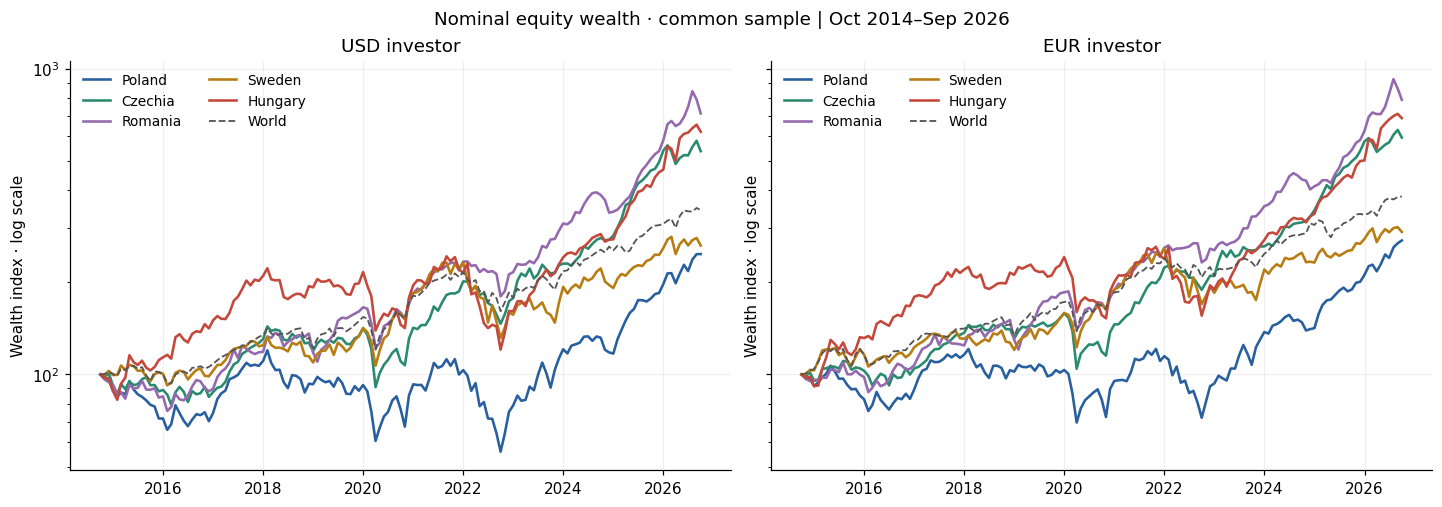

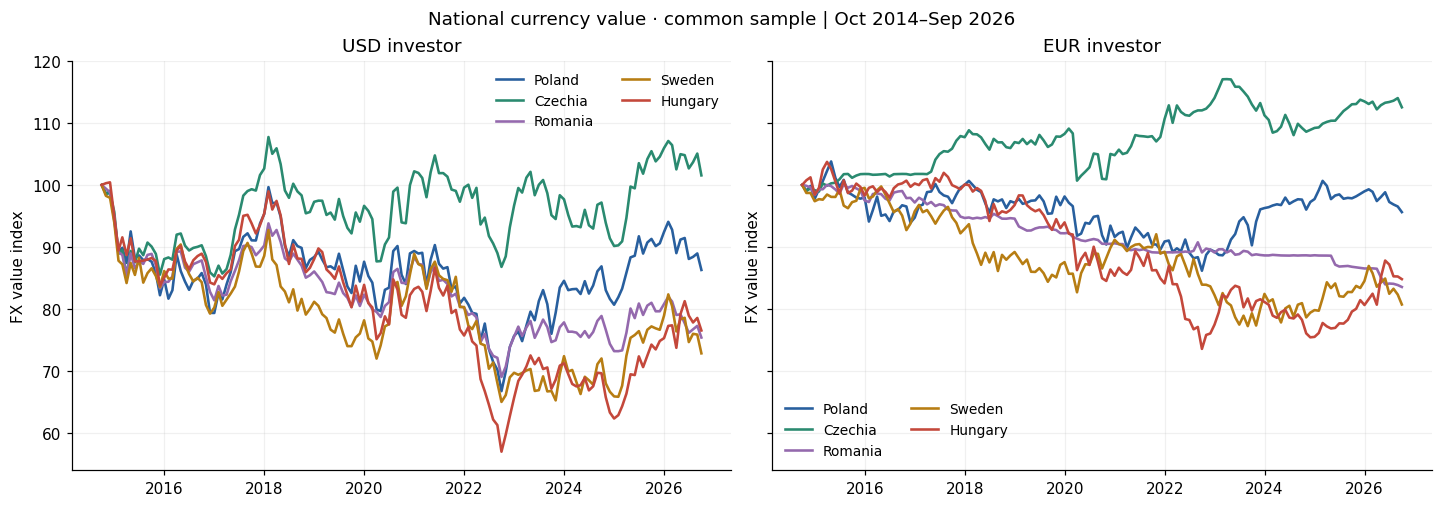

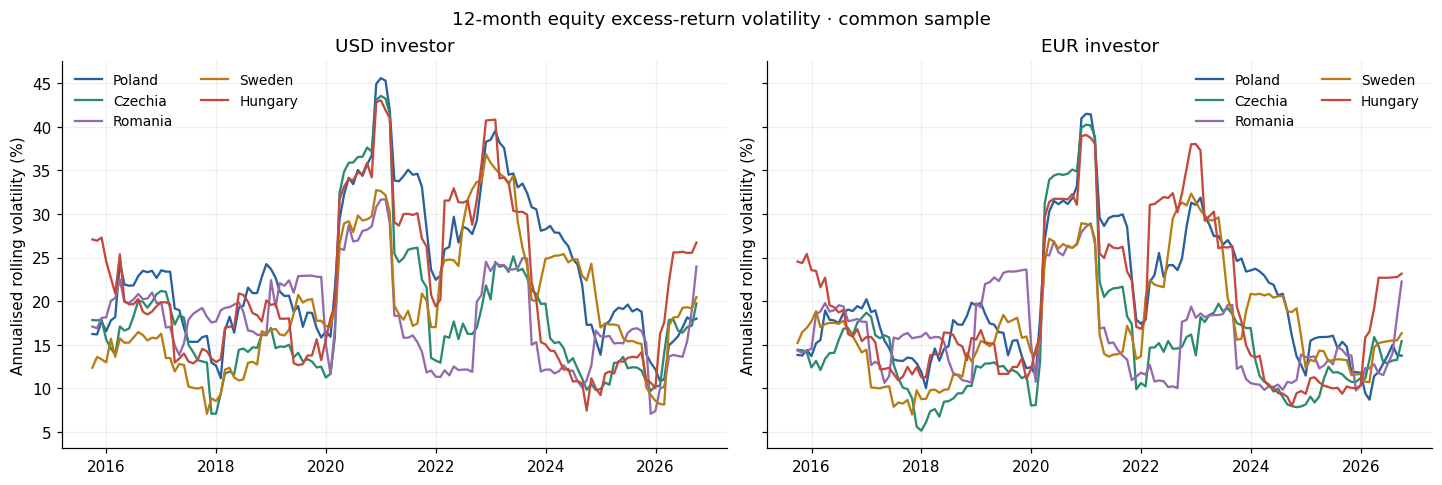

In [4]:
figure_files, rolling_rows, path_rows = [], [], []
dates = common_index.to_timestamp("M")
plot_dates = pd.DatetimeIndex([(common_index[0] - 1).to_timestamp("M")]).append(dates)

def save_plot(name):
    path = OUT / name
    plt.savefig(path, dpi=170, bbox_inches="tight", metadata={"Software": "Regional diagnostics notebook 20"})
    figure_files.append(name)
    plt.show()
    plt.close()

for field, filename, title, ylabel in [
    ("r_local", "01_common_wealth.png", "Nominal equity wealth · common sample", "Wealth index · log scale"),
    ("fx_local", "02_common_fx_paths.png", "National currency value · common sample", "FX value index")]:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, layout="constrained")
    for ax, currency in zip(axes, CURRENCIES):
        for country in NAMES:
            d = common[(country, currency)]
            wealth = np.r_[100., 100 * np.exp(d[field].cumsum())]
            ax.plot(plot_dates, wealth, label=NAMES[country], color=COLORS[country], lw=1.7)
            path_rows.extend({"month": str(month), "country": country, "perspective": currency,
                "path": field, "index_value": value} for month, value in zip(plot_dates.to_period("M"), wealth))
        if field == "r_local":
            benchmark = common[("HU", currency)].r_world
            ax.plot(plot_dates, np.r_[100., 100 * np.exp(benchmark.cumsum())], color="#555555", ls="--", label="World", lw=1.2)
        ax.set(title=f"{currency} investor", ylabel=ylabel, yscale="log" if field == "r_local" else "linear")
        ax.legend(frameon=False, ncol=2, fontsize=9)
    fig.suptitle(title + " | Oct 2014–Sep 2026")
    save_plot(filename)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    for country in NAMES:
        d = common[(country, currency)]
        vol = d.rx_local.rolling(VOL_WINDOW, min_periods=VOL_WINDOW).std() * np.sqrt(12) * 100
        ax.plot(dates, vol, color=COLORS[country], label=NAMES[country], lw=1.5)
        rolling_rows.extend({"month": str(month), "country": country, "perspective": currency,
            "metric": "annualised_excess_volatility_pp", "value": value} for month, value in vol.items() if pd.notna(value))
    ax.set(title=f"{currency} investor", ylabel="Annualised rolling volatility (%)")
    ax.legend(frameon=False, ncol=2, fontsize=9)
fig.suptitle(f"{VOL_WINDOW}-month equity excess-return volatility · common sample")
save_plot("03_common_rolling_volatility.png")

## 4. Equity–world and equity–FX dependence

Report factor covariances/correlations for each country and both windows. Covariances use returns in
percentage points, so their units are **squared monthly percentage points**. The heatmap and rolling
charts use the matched window. Foreign-currency equity returns mechanically include their currency
factor. These are unconditional sample moments; they are not the conditional covariances or risk
prices in the paper's model.

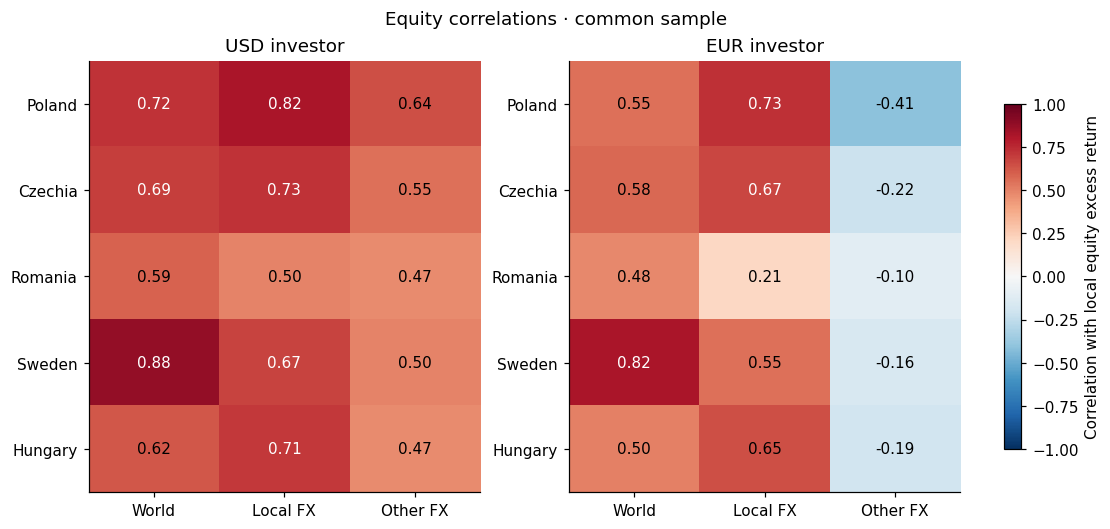

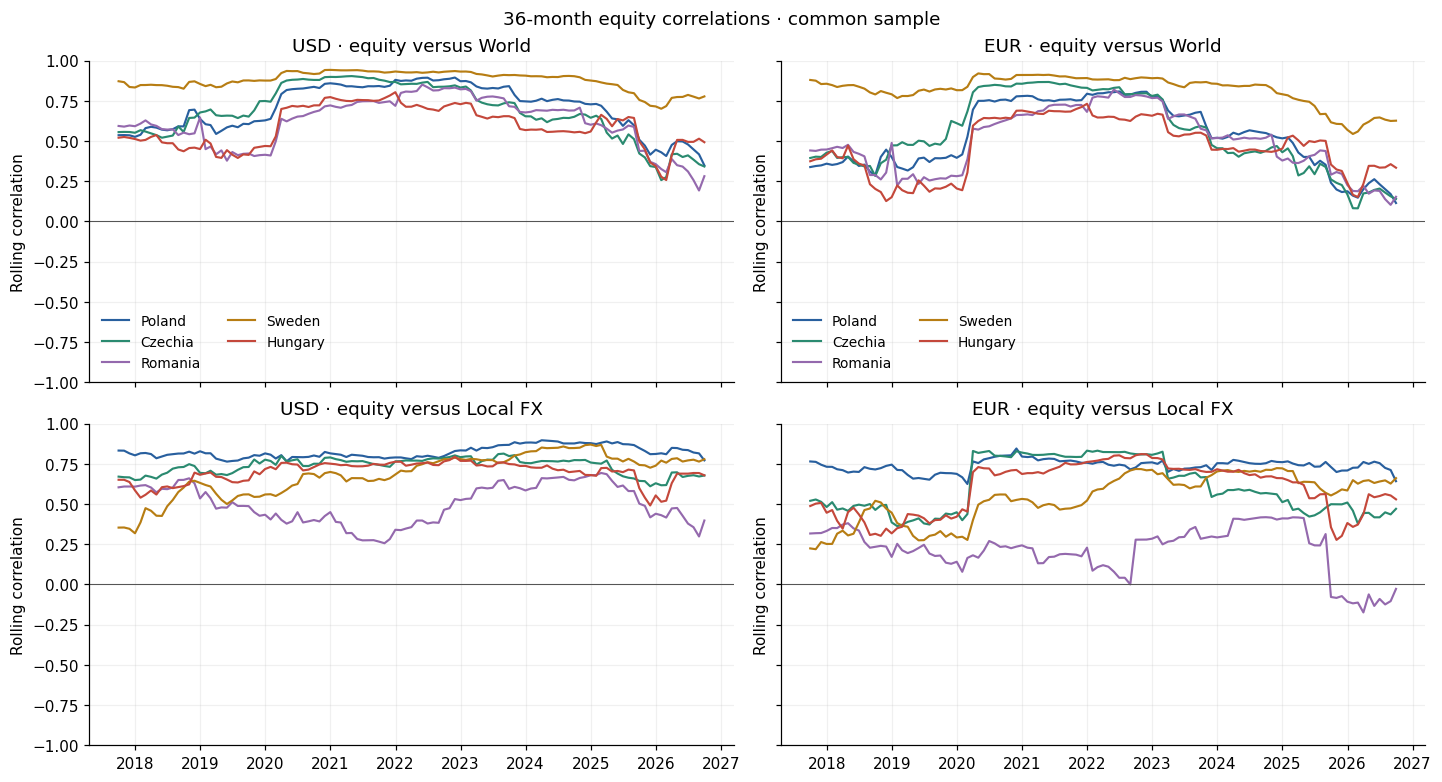

In [5]:
moment_rows, link_rows = [], []
for sample, frames in samples.items():
    for (country, currency), d in frames.items():
        factors = d[list(FACTORS)] * 100
        covariance, correlation = factors.cov(), factors.corr()
        for left in FACTORS:
            for right in FACTORS:
                moment_rows.append({"sample": sample, "country": country, "perspective": currency,
                    "left": left, "right": right, "covariance_pp2": covariance.loc[left, right],
                    "correlation": correlation.loc[left, right]})
        link_rows.append({"sample": sample, "country": country, "perspective": currency,
            "world_correlation": correlation.loc["rx_local", "rx_world"],
            "local_fx_correlation": correlation.loc["rx_local", "fx_local"],
            "other_fx_correlation": correlation.loc["rx_local", "fx_other"],
            "local_fx_covariance_pp2": covariance.loc["rx_local", "fx_local"]})
moments, links = pd.DataFrame(moment_rows), pd.DataFrame(link_rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.7), layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    panel = links.query("sample == 'common' and perspective == @currency").set_index("country").loc[list(NAMES),
        ["world_correlation", "local_fx_correlation", "other_fx_correlation"]]
    image = ax.imshow(panel, vmin=-1, vmax=1, cmap="RdBu_r", aspect="auto")
    ax.set(xticks=range(3), xticklabels=["World", "Local FX", "Other FX"],
        yticks=range(5), yticklabels=list(NAMES.values()), title=f"{currency} investor")
    ax.grid(False)
    for i in range(5):
        for j in range(3):
            value = panel.iloc[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > .65 else "black")
fig.colorbar(image, ax=axes, shrink=.8, label="Correlation with local equity excess return")
fig.suptitle("Equity correlations · common sample")
save_plot("04_common_correlations.png")

fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True, layout="constrained")
for column, currency in enumerate(CURRENCIES):
    for row, (factor, label) in enumerate([("rx_world", "World"), ("fx_local", "Local FX")]):
        ax = axes[row, column]
        for country in NAMES:
            d = common[(country, currency)]
            corr = d.rx_local.rolling(CORR_WINDOW, min_periods=CORR_WINDOW).corr(d[factor])
            ax.plot(dates, corr, color=COLORS[country], label=NAMES[country], lw=1.4)
            rolling_rows.extend({"month": str(month), "country": country, "perspective": currency,
                "metric": f"correlation_{factor}", "value": value} for month, value in corr.items() if pd.notna(value))
        ax.axhline(0, color="#555555", lw=.7)
        ax.set(title=f"{currency} · equity versus {label}", ylim=(-1, 1), ylabel="Rolling correlation")
        if row == 0: ax.legend(frameon=False, ncol=2, fontsize=9)
fig.suptitle(f"{CORR_WINDOW}-month equity correlations · common sample")
save_plot("05_common_rolling_correlations.png")

## 5. Time-series tests and how to read their p-values

Use the same **AR(1) mean with an intercept** as notebook 02, separately for each of the five factors.
This is a diagnostic mean equation, not an asset-pricing model.

| Test | Null hypothesis | Specification |
|---|---|---|
| Ljung–Box, returns | No autocorrelation through the selected lag | Raw return series, demeaned by the test |
| Ljung–Box, AR(1) residuals | No remaining autocorrelation | `model_df=1` for the fitted AR lag |
| ARCH LM, AR(1) residuals | No ARCH effects through the selected lag | `ddof=2` for the intercept and slope, as in notebook 02 |
| ADF, returns | Unit root | Constant, AIC lag selection up to `TEST_LAGS` |

Save test statistics, p-values, effective sample sizes and chosen ADF lags. **Small p-values reject
the stated null; large p-values do not establish it.** ADF rejection is not proof of full stationarity;
ARCH non-rejection does not establish constant conditional variance. These are asymptotic screens:
heavy tails, mean misspecification and breaks can affect calibration and power in 144 observations.

Show raw and **Holm-adjusted** p-values. Each adjustment family is one test type × sample scope ×
investor currency. Identical series on identical dates are tested once in each family (the shared
world, US and other-FX factors are not counted five times). Adjustment is not across all tests or
both numeraires; USD/EUR evidence is dependent. Keep lag choices fixed, rather than searching for
significance. Fit the joint pricing/covariance model before drawing conclusions about priced risks.

Methods: [Ljung–Box](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html),
[ARCH LM](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.het_arch.html),
[ADF](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html),
[Holm adjustment](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html).

In [6]:
test_rows, assignments, test_cache = [], [], {}
P_COLUMNS = ["LB_return_p", "LB_AR1_residual_p", "ARCH_LM_p", "ADF_return_p"]

def series_key(s):
    return (str(s.index[0]), str(s.index[-1]), sha(np.asarray(s, dtype="<f8").tobytes()))

for sample, frames in samples.items():
    for (country, currency), d in frames.items():
        for factor in FACTORS:
            s = d[factor]
            key = (sample, currency, factor, *series_key(s))
            if key not in test_cache:
                ar = pd.concat([s.rename("y"), s.shift(1).rename("lag1")], axis=1).dropna()
                fit = OLS(ar.y, add_constant(ar[["lag1"]], has_constant="add")).fit()
                lb = acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).iloc[0]
                lbr = acorr_ljungbox(fit.resid, lags=[TEST_LAGS], model_df=1, return_df=True).iloc[0]
                arch = het_arch(fit.resid, nlags=TEST_LAGS, ddof=2, result_object=False)
                adf = adfuller(s, maxlag=TEST_LAGS, regression="c", autolag="AIC", result_object=False)
                test_id = len(test_rows)
                test_cache[key] = test_id
                test_rows.append({"test_id": test_id, "sample": sample, "perspective": currency,
                    "series": factor, "first": str(s.index[0]), "last": str(s.index[-1]),
                    "n": len(s), "AR1_residual_n": len(fit.resid), "AR1_slope": fit.params.lag1,
                    "test_lags": TEST_LAGS, "LB_residual_df": TEST_LAGS - 1,
                    "LB_return_stat": lb.lb_stat, "LB_return_p": lb.lb_pvalue,
                    "LB_AR1_residual_stat": lbr.lb_stat, "LB_AR1_residual_p": lbr.lb_pvalue,
                    "ARCH_LM_stat": arch[0], "ARCH_LM_p": arch[1],
                    "ARCH_effective_n": len(fit.resid) - TEST_LAGS,
                    "ADF_return_stat": adf[0], "ADF_return_p": adf[1],
                    "ADF_used_lags": adf[2], "ADF_effective_n": adf[3]})
            assignments.append({"sample": sample, "country": country, "perspective": currency,
                "series": factor, "test_id": test_cache[key]})

unique_tests = pd.DataFrame(test_rows)
for _, indices in unique_tests.groupby(["sample", "perspective"]).groups.items():
    for p in P_COLUMNS:
        unique_tests.loc[indices, p + "_holm"] = multipletests(unique_tests.loc[indices, p], method="holm")[1]
    unique_tests.loc[indices, "family_unique_series"] = len(indices)
diagnostics = pd.DataFrame(assignments).merge(unique_tests,
    on=["test_id", "sample", "perspective", "series"], validate="many_to_one")
assert np.isfinite(unique_tests[P_COLUMNS].to_numpy()).all()
assert unique_tests[P_COLUMNS].ge(0).all().all() and unique_tests[P_COLUMNS].le(1).all().all()
assert (unique_tests[[p + "_holm" for p in P_COLUMNS]].to_numpy() + 1e-15 >= unique_tests[P_COLUMNS].to_numpy()).all()

for factor, label in [("rx_local", "Equity excess returns"), ("fx_local", "National currency returns")]:
    display(Markdown(f"**{label} · common sample**"))
    table = diagnostics.query("sample == 'common' and series == @factor").set_index(["country", "perspective"])
    columns = ["AR1_slope", "LB_AR1_residual_p", "LB_AR1_residual_p_holm",
               "ARCH_LM_p", "ARCH_LM_p_holm", "ADF_return_p", "ADF_used_lags"]
    display(table[columns].style.format({c: "{:.3g}" for c in columns}))
print("Unique test series per family:", unique_tests.groupby(["sample", "perspective"]).size().to_dict())

**Equity excess returns · common sample**

**National currency returns · common sample**

Unique test series per family: {('available', 'EUR'): 22, ('available', 'USD'): 22, ('common', 'EUR'): 13, ('common', 'USD'): 13}


## 6. Conditioning variables, rank and quality flags

Inspect the already-lagged global predictors, local inflation-gap level and change, and other-FX
inflation-gap level. Do not shift them again. Predictor ADF p-values are **unadjusted persistence
screens**, not a variable-selection rule. Exclude regime and quality flags from unit-root testing.
The Hungarian full sample has one unavailable initial gap change because the frozen working data
start in January 2000: retain all equity returns, show the predictor's actual coverage, and exclude
that one row only from designs that require the change. No such gap occurs in the common sample.

Standardise each candidate design on its **own estimation window**, add an intercept, exclude
constant columns and report rank/condition number. These checks do not select a final instrument
set. Regime definitions are country-specific: Poland has only four pre-float observations in its
full sample and no variation in the common window; Czechia has the exchange-rate-floor indicator;
Romania and Sweden have zero placeholders. Hungary's flag is constant in the common window.

The inherited inflation carry flag marks **December 2025** at the lagged level. USD local-gap
changes are affected in **December 2025 and January 2026**; EUR local-gap changes are unaffected by
US CPI. Both perspectives' other-FX gap levels are affected in December. Return diagnostics retain
these months because market returns were not filled. Keep these dates for later instrument-sensitivity
checks. Czech back-calculated returns remain flagged in its full history and are absent in the common window.

In [7]:
predictor_rows, rank_rows, quality_rows, adf_cache = [], [], [], {}
predictor_columns = GLOBAL_Z + ["inflation_gap_lag2_pp", "inflation_gap_change_lag2_pp", "other_fx_gap_lag2_pp"]
designs = {"global": GLOBAL_Z,
    "local_FX_candidates": GLOBAL_Z + ["inflation_gap_change_lag2_pp", "regime_indicator"],
    "other_FX_candidates": GLOBAL_Z + ["other_fx_gap_lag2_pp"],
    "combined_candidates": GLOBAL_Z + ["inflation_gap_change_lag2_pp", "other_fx_gap_lag2_pp", "regime_indicator"]}
for sample, frames in samples.items():
    for (country, currency), d in frames.items():
        for name in predictor_columns:
            s = d[name].dropna()
            assert s.index.equals(pd.period_range(s.index[0], s.index[-1], freq="M"))
            key = series_key(s)
            if key not in adf_cache:
                adf_cache[key] = adfuller(s, maxlag=TEST_LAGS, regression="c", autolag="AIC", result_object=False)
            adf = adf_cache[key]
            predictor_rows.append({"sample": sample, "country": country, "perspective": currency,
                "predictor": name, "n": len(s), "missing_in_return_sample": int(d[name].isna().sum()),
                "first": str(s.index[0]), "last": str(s.index[-1]), "mean_pp": s.mean(), "sd_pp": s.std(),
                "lag1_correlation": s.autocorr(1), "ADF_stat": adf[0], "ADF_p_raw": adf[1],
                "ADF_used_lags": adf[2], "ADF_effective_n": adf[3]})
        for label, columns in designs.items():
            z = d[columns].dropna()
            varying = [c for c in columns if z[c].nunique() > 1]
            x = np.column_stack([np.ones(len(z)), (z[varying] - z[varying].mean()) / z[varying].std(ddof=0)])
            rank = np.linalg.matrix_rank(x)
            assert rank == x.shape[1], f"Collinear candidates: {sample}, {country}, {currency}, {label}"
            rank_rows.append({"sample": sample, "country": country, "perspective": currency, "design": label,
                "n": len(z), "first": str(z.index[0]), "rank": rank, "columns_with_intercept": x.shape[1],
                "condition_number": np.linalg.cond(x), "constant_excluded": "; ".join(c for c in columns if c not in varying),
                "regime_zeros": int(z.regime_indicator.eq(0).sum()) if "regime_indicator" in z else None,
                "regime_ones": int(z.regime_indicator.eq(1).sum()) if "regime_indicator" in z else None})
        carried = d.flag_us_inflation_carried_lag2.eq(1)
        changed = carried | carried.shift(1, fill_value=False)
        quality_rows.append({"sample": sample, "country": country, "perspective": currency,
            "known_backcast_months": int(d.flag_known_index_backcast.sum()),
            "lagged_inflation_level_carry_dates": "; ".join(map(str, d.index[carried])),
            "local_gap_change_carry_dates": "; ".join(map(str, d.index[changed])) if currency == "USD" else "",
            "other_FX_gap_level_carry_dates": "; ".join(map(str, d.index[carried]))})
predictors, instrument_rank, quality_flags = map(pd.DataFrame, [predictor_rows, rank_rows, quality_rows])
display(predictors.query("sample == 'common' and predictor == 'inflation_gap_change_lag2_pp'")
    .set_index(["country", "perspective"])[["n", "sd_pp", "lag1_correlation", "ADF_p_raw", "ADF_used_lags"]].round(4))
display(instrument_rank.query("sample == 'common' and design == 'combined_candidates'")
    .set_index(["country", "perspective"])[["n", "rank", "columns_with_intercept", "condition_number", "constant_excluded"]].round(3))
display(quality_flags.query("sample == 'common'").drop(columns=["sample", "known_backcast_months"]))

n   sd_pp  lag1_correlation  ADF_p_raw  ADF_used_lags
country perspective                                                         
PL      USD          144  0.5519            0.4913     0.0000             11
        EUR          144  0.4583            0.2775     0.0031             12
CZ      USD          144  0.7943            0.1929     0.0002             11
        EUR          144  0.8234            0.0389     0.0084             11
RO      USD          144  0.6086            0.2306     0.0032             12
        EUR          144  0.5691            0.0366     0.0000             11
SE      USD          144  0.5841            0.0764     0.0000             11
        EUR          144  0.5274           -0.1906     0.0000              1
HU      USD          144  0.8731            0.7581     0.0042             12
        EUR          144  0.8159            0.5619     0.0008             12

n  rank  columns_with_intercept  condition_number  \
country perspective                                                        
PL      USD          144     6                       6             2.123   
        EUR          144     6                       6             2.097   
CZ      USD          144     7                       7             2.207   
        EUR          144     7                       7             2.192   
RO      USD          144     6                       6             2.093   
        EUR          144     6                       6             2.073   
SE      USD          144     6                       6             2.137   
        EUR          144     6                       6             2.102   
HU      USD          144     6                       6             2.203   
        EUR          144     6                       6             2.164   

                    constant_excluded  
country perspective                    
PL      USD          regime_indicator  
        EUR          regime_indicator  
CZ      USD                            
        EUR                            
RO      USD          regime_indicator  
        EUR          regime_indicator  
SE      USD          regime_indicator  
        EUR          regime_indicator  
HU      USD          regime_indicator  
        EUR          regime_indicator

,country,perspective,lagged_inflation_level_carry_dates,local_gap_change_carry_dates,other_FX_gap_level_carry_dates
10,PL,USD,2025-12,2025-12; 2026-01,2025-12
11,PL,EUR,2025-12,,2025-12
12,CZ,USD,2025-12,2025-12; 2026-01,2025-12
13,CZ,EUR,2025-12,,2025-12
14,RO,USD,2025-12,2025-12; 2026-01,2025-12
15,RO,EUR,2025-12,,2025-12
16,SE,USD,2025-12,2025-12; 2026-01,2025-12
17,SE,EUR,2025-12,,2025-12
18,HU,USD,2025-12,2025-12; 2026-01,2025-12
19,HU,EUR,2025-12,,2025-12


## 7. Common-sample comparison with Hungary

The final table compares the same 144 months for each investor perspective. The equity–FX covariance
is an observed sample moment; **its sign alone does not identify the FX premium's sign**. The local
currency equity mean is reconstructed by subtracting the observed FX change from the investor's total
equity return. The realised mean identity is `local equity mean + FX mean − cash mean = excess mean`.

The comparison against Hungary is paired by month. Report the mean relative return, correlation and
tracking-error volatility; this is a descriptive comparison, without a country-performance significance
test or a causal claim. Different sector weights, dividend-tax conventions and market coverage remain.

In [8]:
comparison_rows = []
for currency in CURRENCIES:
    benchmark = common[("HU", currency)].rx_local
    for country in NAMES:
        d = common[(country, currency)]
        fx, equity = d.fx_local, d.rx_local
        residual = equity - benchmark
        comparison_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "months": len(d), "mean_excess_monthly_log_pp": equity.mean() * 100,
            "vol_annualised_pp": equity.std() * np.sqrt(12) * 100,
            "mean_local_currency_total_log_pp": (d.r_local - fx).mean() * 100,
            "mean_FX_monthly_log_pp": fx.mean() * 100, "mean_cash_monthly_log_pp": d.rf.mean() * 100,
            "world_correlation": equity.corr(d.rx_world), "local_FX_correlation": equity.corr(fx),
            "local_FX_covariance_pp2": (equity * 100).cov(fx * 100),
            "correlation_with_HU": equity.corr(benchmark),
            "mean_relative_to_HU_monthly_log_pp": residual.mean() * 100,
            "tracking_error_vs_HU_annualised_pp": residual.std() * np.sqrt(12) * 100})
comparison = pd.DataFrame(comparison_rows)
np.testing.assert_allclose(comparison.mean_excess_monthly_log_pp,
    comparison.mean_local_currency_total_log_pp + comparison.mean_FX_monthly_log_pp - comparison.mean_cash_monthly_log_pp,
    atol=1e-12, rtol=0)
equity_tests = diagnostics.query("sample == 'common' and series == 'rx_local'")
comparison = comparison.merge(equity_tests[["country", "perspective", "LB_AR1_residual_p", "LB_AR1_residual_p_holm",
    "ARCH_LM_p", "ARCH_LM_p_holm", "ADF_return_p"]], on=["country", "perspective"], validate="one_to_one")
display(comparison.set_index(["name", "perspective"])[["mean_excess_monthly_log_pp", "vol_annualised_pp",
    "world_correlation", "local_FX_correlation", "local_FX_covariance_pp2",
    "mean_relative_to_HU_monthly_log_pp", "tracking_error_vs_HU_annualised_pp"]].round(3))

reading = []
for currency in CURRENCIES:
    table = comparison.query("perspective == @currency")
    most = table.loc[table.vol_annualised_pp.idxmax()]
    least = table.loc[table.vol_annualised_pp.idxmin()]
    local_tests = equity_tests.query("perspective == @currency")
    mean_rejections = local_tests.loc[local_tests.LB_AR1_residual_p_holm < ALPHA, "country"].map(NAMES).tolist()
    arch_rejections = local_tests.loc[local_tests.ARCH_LM_p_holm < ALPHA, "country"].map(NAMES).tolist()
    reading.append(f"- **{currency}:** highest equity volatility {most['name']} ({most.vol_annualised_pp:.1f}%), "
        f"lowest {least['name']} ({least.vol_annualised_pp:.1f}%). After Holm adjustment, AR(1) residual "
        f"autocorrelation is flagged for **{', '.join(mean_rejections) or 'none'}**; ARCH is flagged for "
        f"**{', '.join(arch_rejections) or 'none'}** at {100 * ALPHA:g}%.")
display(Markdown("**Reading this run — common sample**\n\n" + "\n".join(reading) +
    "\n\nNon-rejection is not evidence of no time-varying risk. The 144-month comparison has less power than "
    "the longer Hungarian analysis. These diagnostics do not estimate risk prices, hedge returns or an economic drag."))

,,mean_excess_monthly_log_pp,vol_annualised_pp,world_correlation,local_FX_correlation,local_FX_covariance_pp2,mean_relative_to_HU_monthly_log_pp,tracking_error_vs_HU_annualised_pp
name,perspective,,,,,,,
Poland,USD,0.466,24.912,0.719,0.816,17.382,-0.639,16.833
Czechia,USD,1.003,19.923,0.694,0.725,11.039,-0.102,16.717
Romania,USD,1.201,19.284,0.591,0.500,6.053,0.096,20.799
Sweden,USD,0.510,20.608,0.876,0.673,11.874,-0.595,20.071
Hungary,USD,1.105,23.987,0.622,0.708,14.811,0.000,0.000
Poland,EUR,0.646,20.990,0.549,0.730,6.616,-0.639,16.833
Czechia,EUR,1.183,17.009,0.576,0.667,3.703,-0.102,16.717
Romania,EUR,1.381,17.124,0.483,0.207,0.542,0.096,20.799
Sweden,EUR,0.690,18.102,0.815,0.550,4.914,-0.595,20.071


**Reading this run — common sample**

- **USD:** highest equity volatility Poland (24.9%), lowest Romania (19.3%). After Holm adjustment, AR(1) residual autocorrelation is flagged for **none**; ARCH is flagged for **none** at 5%.
- **EUR:** highest equity volatility Hungary (21.5%), lowest Czechia (17.0%). After Holm adjustment, AR(1) residual autocorrelation is flagged for **none**; ARCH is flagged for **none** at 5%.

Non-rejection is not evidence of no time-varying risk. The 144-month comparison has less power than the longer Hungarian analysis. These diagnostics do not estimate risk prices, hedge returns or an economic drag.

## 8. Save the diagnostics and move to the pricing baseline

Save full-precision tables, the underlying chart series and five figures locally. Record settings,
package versions and input/output hashes. Recheck every frozen input after analysis; no original
snapshot or model result is written. Re-running with the same settings overwrites only notebook 20's
derived outputs. A change of settings is recorded in the output manifest.

**Next:** estimate a parsimonious joint pricing baseline for each country, using a consistent
common-window specification with Hungary as the reference and keeping longer histories separate.
Inspect numerical identification and fitted residuals before extending risk-price dynamics or
interpreting cross-country FX-premium differences. A full five-factor covariance system can be
parameter-heavy for 144 months; instrument rank alone does not establish model identification.

In [9]:
tables = {"sample_audit.csv": sample_audit, "descriptive_statistics.csv": descriptive,
    "factor_moments.csv": moments, "equity_factor_links.csv": links,
    "time_series_diagnostics.csv": diagnostics, "unique_test_families.csv": unique_tests,
    "predictor_diagnostics.csv": predictors, "instrument_rank.csv": instrument_rank,
    "quality_flags.csv": quality_flags, "common_comparison.csv": comparison,
    "chart_paths.csv": pd.DataFrame(path_rows), "chart_rolling.csv": pd.DataFrame(rolling_rows)}
for name, frame in tables.items():
    frame.to_csv(OUT / name, index=False, float_format="%.17g", lineterminator="\n")
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes
metadata = {"notebook": "20_regional_diagnostics.ipynb", "endpoint": END_MONTH,
    "common_start": str(common_index[0]), "common_months": len(common_index),
    "settings": {"VOL_WINDOW": VOL_WINDOW, "CORR_WINDOW": CORR_WINDOW, "TEST_LAGS": TEST_LAGS, "ALPHA": ALPHA},
    "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "regional_manifest_sha256": regional["manifest_sha256"],
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT / name).read_bytes()) for name in [*tables, *figure_files]},
    "notes": ["Offline; inputs verified unchanged before and after diagnostics",
        "Monthly log returns; unhedged USD/EUR; primary comparison uses identical 144 months",
        "Holm within test type, sample and currency, deduplicating identical factor series",
        "Hungary has one initial missing change predictor; all 321 return months retained"]}
(OUT / "diagnostics_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True) + "\n")
display(Markdown(f"**Completed:** five countries × two investor perspectives; "
    f"common window **{common_index[0]}–{common_index[-1]} ({len(common_index)} months)**. "
    f"Saved **{len(tables)} tables and {len(figure_files)} charts** in `{OUT.relative_to(ROOT)}`. "
    "All frozen regional and original Hungarian inputs verified unchanged."))

**Completed:** five countries × two investor perspectives; common window **2014-10–2026-09 (144 months)**. Saved **12 tables and 5 charts** in `output/20_regional_diagnostics/fixed_2026-09`. All frozen regional and original Hungarian inputs verified unchanged.